# Week 7: The Adaptation Decision and a Production Dataset
This week's project frames how an AI engineer should decide to adapt an AI system when its behavior or output quality does not meet the standard required for a task. It can often feel like the right move is to fine-tune a model. However, fine-tuning is the most costly option in the AI engineer's toolbelt, so the adaptation decision should begin by ruling out simpler options. Prompting, retrieval-augmented generation (RAG), and doing nothing should each be considered before fine-tuning is shown to be necessary for reaching the performance goals.

In this project, I choose a task that I want my AI to perform better and use Microsoft Foundry to generate a synthetic dataset that could be used for fine-tuning. Before committing to fine-tuning, I test dynamic few-shot prompting. For each question in the held-out evaluation set, I retrieve the most similar samples from the training set and add them to the prompt before the model generates an answer. This shows whether giving the model training samples with ground truth answers is enough to improve performance.

I then evaluate the outputs with an LLM as judge, comparing zero-shot answers against dynamic few-shot answers. I chose this method because my dataset consists of open-ended question and answer pairs rather than labeled classification data, so scoring each answer against its reference answer was the fairest way to measure quality. Finally, I close with an adaptation memo that uses the results to explain whether fine-tuning is appropriate for this task.



## Project Task

The task I want the AI to perform better is answering developer questions about the Microsoft Agent Framework Python API. Given a question about a specific class, function, or parameter in the API reference, the model should give an accurate answer that explains what it is for, how it behaves, and how it is used. This includes documented details such as defaults, return types, and exceptions. Developers rely on these answers to use the framework correctly, so the answers need to be precise and consistent with the documentation rather than general or guessed. This is the behavior I want to improve, and it is the reason I am considering fine-tuning in the first place.

## Part 1: Prepare the Dataset

This section documents how I used Microsoft Foundry to generate synthetic fine-tuning examples. I created the samples from the Microsoft Agent Framework Python API reference PDF, which I retrieved from Microsoft Learn.

**Microsoft Source References:**
* [Microsoft Learn Agent Framework Python Webpage](https://learn.microsoft.com/en-us/python/api/agent-framework-core/agent_framework?view=agent-framework-python-latest)
* [Full agent_framework Package PDF that I downloaded](https://learn.microsoft.com/pdf?url=https%3A%2F%2Flearn.microsoft.com%2Fen-us%2Fpython%2Fapi%2Fagent-framework-python-ref-toc%2Ftoc.json%3Fview%3Dagent-framework-python-latest)


### Synthetic Data Generation Procedure

I generated the fine-tuning examples in Microsoft Foundry from the Agent Framework Python API reference. Because the full reference is 2,423 pages, I split it into three smaller PDF parts and generated each part separately.

1. In **Data > Data generation**, choose **Generate synthetic data** and select **Supervised fine-tuning**.
2. Set the task to **Simple Q&A (single turn)**, the question type to **Short answer**, and the generator to **GPT-5.4**. Upload one PDF part as the reference file and set the maximum number of samples to **150**.
3. Leave **Split data into training and validation sets** enabled, name the output, and generate the dataset. Repeat for all three PDF parts.
4. Foundry produced separate training and validation files for each part: **361 examples total** across the three runs. Although I used the split option during generation, I will merge the training and validation files into one dataset for this project.

<div align="center">
  <img src="data/images/generate_synthetic_data_1.png" alt="Microsoft Foundry data generation jobs for the three PDF parts" width="900">
</div>
<p align="center"><em>Three successful synthetic-data generation jobs and their output row counts.</em></p>

<div align="center">
  <img src="data/images/generate_synthetic_data_2.png" alt="Microsoft Foundry synthetic data generation settings" width="360">
</div>
<p align="center"><em>Generation settings used for a PDF part, including the enabled training and validation split.</em></p>

### Combine Source JSONL Files
* Uncomment if needing to combine them

In [1]:
# import json
# from pathlib import Path


# def combine_maf_samples(
#     data_dir: Path | None = None,
# ) -> list[dict[str, object]]:
#     """Combine the six MAF training and validation JSONL files.

#     Args:
#         data_dir: Directory containing the six source JSONL files. When omitted,
#             searches from either the repository root or the week-7 directory.

#     Output:
#         The combined records as a list of dictionaries. The same records are
#         written to combined-all-MAF-samples.jsonl in data_dir, one JSON object
#         per line.
#     """
#     if data_dir is None:
#         candidate_dirs = (
#             Path("week-7/data/foundry-synthetic-generated-data"),
#             Path("data/foundry-synthetic-generated-data"),
#         )
#         data_dir = next(
#             (candidate for candidate in candidate_dirs if candidate.is_dir()),
#             candidate_dirs[0],
#         )

#     source_files = sorted(data_dir.glob("simpleqna_supervised_*MAF*_*.jsonl"))
#     if len(source_files) != 6:
#         raise ValueError(
#             f"Expected 6 MAF JSONL source files in {data_dir}, found {len(source_files)}."
#         )

#     combined_samples = []
#     for source_file in source_files:
#         with source_file.open("r", encoding="utf-8") as input_file:
#             for line_number, line in enumerate(input_file, start=1):
#                 if not line.strip():
#                     continue
#                 sample = json.loads(line)
#                 if not isinstance(sample, dict):
#                     raise ValueError(
#                         f"Expected a JSON object in {source_file} on line {line_number}."
#                     )
#                 combined_samples.append(sample)

#     output_path = data_dir / "combined-all-MAF-samples.jsonl"
#     with output_path.open("w", encoding="utf-8") as output_file:
#         for sample in combined_samples:
#             output_file.write(json.dumps(sample, ensure_ascii=False) + "\n")

#     return combined_samples


# combined_maf_samples = combine_maf_samples()
# print(f"Saved {len(combined_maf_samples)} samples to combined-all-MAF-samples.jsonl")

### Dataset Pipeline

1. **`read_jsonl_with_report`** reads the original JSONL file and reports blank or malformed lines.
2. **`clean_validate_and_split_data`** filters incomplete records, removes duplicate question-answer pairs, validates the chat-message format, and creates a 311-record training split plus a 50-record held-out evaluation split.
3. **`write_dataset_splits`** saves the already validated records to `maf_training.jsonl` and `maf_evaluation.jsonl`.
4. **`load_jsonl`** loads those saved files into `training_data` and `evaluation_data` for retrieval and evaluation. It does not validate again because validation happened before the files were written.

**Supporting helpers:** `_message_text` extracts a message for a requested role; `_filter_samples`, `_deduplicate_samples`, and `_validate_samples` perform the cleaning steps; `_sample_token_count` reports token-length statistics.

In [2]:
import json
from collections import Counter
from pathlib import Path

import numpy as np
import tiktoken
from sklearn.model_selection import train_test_split


RAW_DATA_PATH = Path("data/foundry-synthetic-generated-data/combined-all-MAF-samples.jsonl")
SPLIT_DIRECTORY = RAW_DATA_PATH.parent / "splits"
TRAINING_DATA_PATH = SPLIT_DIRECTORY / "maf_training.jsonl"
EVALUATION_DATA_PATH = SPLIT_DIRECTORY / "maf_evaluation.jsonl"
EVALUATION_SIZE = 50
SPLIT_RANDOM_STATE = 7


def read_jsonl_with_report(data_path: Path) -> tuple[list[object], Counter]:
    """Read a JSONL file and count blank or malformed lines."""
    if not data_path.is_file():
        raise FileNotFoundError(f"Dataset not found: {data_path}")

    records = []
    report = Counter()
    with data_path.open(encoding="utf-8") as input_file:
        for line in input_file:
            report["lines_seen"] += 1
            if not line.strip():
                report["blank_lines"] += 1
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                report["malformed_json"] += 1

    report["records_read"] = len(records)
    return records, report


def _message_text(sample: dict[str, object], role: str) -> str:
    """Return the first non-empty message text for the requested role."""
    messages = sample.get("messages")
    if not isinstance(messages, list):
        return ""

    for message in messages:
        if (
            isinstance(message, dict)
            and message.get("role") == role
            and isinstance(message.get("content"), str)
            and message["content"].strip()
        ):
            return message["content"].strip()
    return ""


def _filter_samples(samples: list[object]) -> tuple[list[dict[str, object]], Counter]:
    """Keep records with a non-empty user question and assistant answer."""
    filtered_data = []
    report = Counter()

    for sample in samples:
        if not isinstance(sample, dict):
            report["not_json_object"] += 1
        elif not _message_text(sample, "user") or not _message_text(sample, "assistant"):
            report["missing_question_or_answer"] += 1
        else:
            filtered_data.append(sample)

    return filtered_data, report


def _deduplicate_samples(
    samples: list[dict[str, object]],
) -> tuple[list[dict[str, object]], int]:
    """Remove duplicate question-answer pairs, ignoring case and whitespace."""
    unique_data = []
    seen_pairs = set()
    duplicate_count = 0

    for sample in samples:
        question = " ".join(_message_text(sample, "user").casefold().split())
        answer = " ".join(_message_text(sample, "assistant").casefold().split())
        pair = (question, answer)
        if pair in seen_pairs:
            duplicate_count += 1
            continue

        seen_pairs.add(pair)
        unique_data.append(sample)

    return unique_data, duplicate_count


def _validate_samples(
    samples: list[dict[str, object]],
) -> tuple[list[dict[str, object]], Counter]:
    """Require non-empty system, user, and assistant messages in that order."""
    valid_data = []
    report = Counter()
    expected_roles = ["system", "user", "assistant"]

    for sample in samples:
        messages = sample.get("messages")
        roles = [
            message.get("role") if isinstance(message, dict) else None
            for message in messages
        ] if isinstance(messages, list) else []
        contents_valid = isinstance(messages, list) and all(
            isinstance(message, dict)
            and isinstance(message.get("content"), str)
            and bool(message["content"].strip())
            for message in messages
        )

        if set(sample) != {"messages"} or roles != expected_roles or not contents_valid:
            report["invalid_message_format"] += 1
        else:
            valid_data.append(sample)

    return valid_data, report


def _sample_token_count(sample: dict[str, object], encoding) -> int:
    """Count message-text tokens, excluding chat-format overhead."""
    messages = sample.get("messages")
    if not isinstance(messages, list):
        return 0

    return sum(
        len(encoding.encode(message["content"]))
        for message in messages
        if isinstance(message, dict) and isinstance(message.get("content"), str)
    )


def clean_validate_and_split_data(
    data_path: Path = RAW_DATA_PATH,
) -> tuple[list[dict[str, object]], list[dict[str, object]], list[dict[str, object]]]:
    """Clean and validate raw data, then make a held-out evaluation split."""
    raw_data, read_report = read_jsonl_with_report(data_path)
    filtered_data, filter_report = _filter_samples(raw_data)
    unique_data, duplicate_count = _deduplicate_samples(filtered_data)
    clean_data, validation_report = _validate_samples(unique_data)

    if len(clean_data) <= EVALUATION_SIZE:
        raise ValueError(
            f"At least {EVALUATION_SIZE + 1} valid records are needed for the evaluation split."
        )

    encoding = tiktoken.encoding_for_model("gpt-5.4-mini")
    question_lengths = [
        len(encoding.encode(_message_text(sample, "user")))
        for sample in clean_data
    ]
    length_bins = np.unique(np.quantile(question_lengths, [0.25, 0.5, 0.75]))
    length_buckets = np.digitize(question_lengths, length_bins)

    if min(Counter(length_buckets).values()) < 2:
        length_buckets = (np.asarray(question_lengths) > np.median(question_lengths)).astype(int)
    if min(Counter(length_buckets).values()) < 2:
        length_buckets = np.zeros(len(clean_data), dtype=int)

    training_indices, evaluation_indices = train_test_split(
        np.arange(len(clean_data)),
        test_size=EVALUATION_SIZE,
        random_state=SPLIT_RANDOM_STATE,
        stratify=length_buckets,
    )
    training_data = [clean_data[index] for index in training_indices]
    evaluation_data = [clean_data[index] for index in evaluation_indices]

    print("========================= DATA QUALITY REPORT =========================\n")
    print(f"JSONL lines: {read_report['lines_seen']}")
    print(f"Parsed records: {read_report['records_read']}")
    print(f"Blank lines: {read_report['blank_lines']}")
    print(f"Malformed JSON lines: {read_report['malformed_json']}")
    print(f"Filtered records: {sum(filter_report.values())}")
    print(f"Duplicate Q&A pairs removed: {duplicate_count}")
    print(f"Invalid formats: {sum(validation_report.values())}")
    print(f"Clean records: {len(clean_data)}")
    print(f"Training records: {len(training_data)}")
    print(f"Evaluation records: {len(evaluation_data)}")
    print("Label balance: not applicable; MAF records have no label field.")

    for split_name, split_data in (
        ("All clean", clean_data),
        ("Training", training_data),
        ("Evaluation", evaluation_data),
    ):
        token_counts = [_sample_token_count(sample, encoding) for sample in split_data]
        print(
            f"{split_name} message tokens: min={min(token_counts)}, "
            f"median={np.median(token_counts):.0f}, "
            f"mean={np.mean(token_counts):.1f}, "
            f"p90={np.percentile(token_counts, 90):.0f}, "
            f"max={max(token_counts)}"
        )

    print(f"Format consistency: {len(clean_data)}/{len(unique_data)} records passed validation.")
    print("\n=======================================================================")
    return clean_data, training_data, evaluation_data


def write_jsonl(data: list[dict[str, object]], data_path: Path) -> None:
    """Write validated chat-message records as one JSON object per line."""
    with data_path.open("w", encoding="utf-8") as output_file:
        for record in data:
            output_file.write(json.dumps(record, ensure_ascii=False) + "\n")


def write_dataset_splits(
    training_data: list[dict[str, object]],
    evaluation_data: list[dict[str, object]],
) -> None:
    """Write the clean training and held-out evaluation splits as JSONL."""
    SPLIT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    write_jsonl(training_data, TRAINING_DATA_PATH)
    write_jsonl(evaluation_data, EVALUATION_DATA_PATH)


def load_jsonl(data_path: Path) -> list[dict[str, object]]:
    """Load a JSONL split that was validated before being written."""
    with data_path.open(encoding="utf-8") as input_file:
        return [json.loads(line) for line in input_file if line.strip()]


In [3]:
clean_data, training_data, evaluation_data = clean_validate_and_split_data()
write_dataset_splits(training_data, evaluation_data)
training_data = load_jsonl(TRAINING_DATA_PATH)
evaluation_data = load_jsonl(EVALUATION_DATA_PATH)

print(f"Wrote training split: {TRAINING_DATA_PATH}")
print(f"Wrote evaluation split: {EVALUATION_DATA_PATH}")

========================= DATA QUALITY REPORT =========================

JSONL lines: 361
Parsed records: 361
Blank lines: 0
Malformed JSON lines: 0
Filtered records: 0
Duplicate Q&A pairs removed: 0
Invalid formats: 0
Clean records: 361
Training records: 311
Evaluation records: 50
Label balance: not applicable; MAF records have no label field.
All clean message tokens: min=38, median=118, mean=137.2, p90=236, max=414
Training message tokens: min=44, median=118, mean=137.5, p90=239, max=414
Evaluation message tokens: min=38, median=128, mean=135.1, p90=234, max=279
Format consistency: 361/361 records passed validation.

Wrote training split: data\foundry-synthetic-generated-data\splits\maf_training.jsonl
Wrote evaluation split: data\foundry-synthetic-generated-data\splits\maf_evaluation.jsonl


### Visualize Token Lengths Across Dataset Splits

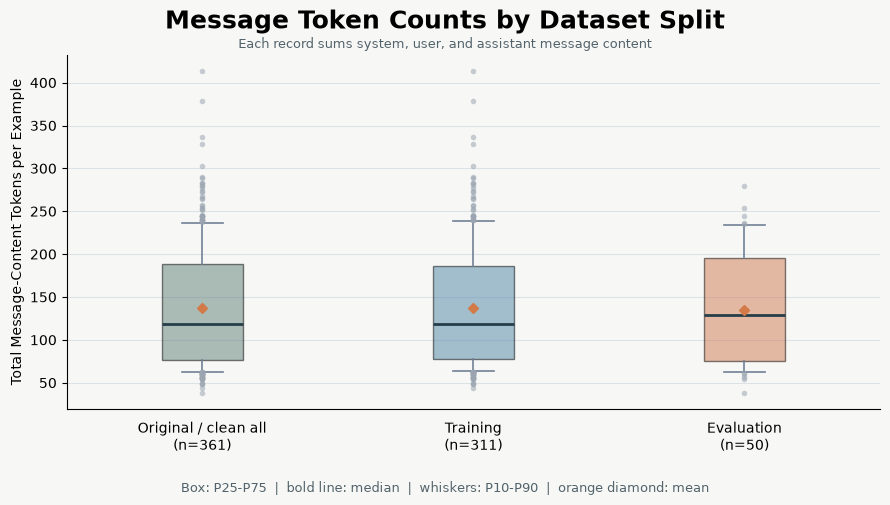

In [4]:
import matplotlib.pyplot as plt

raw_data, _ = read_jsonl_with_report(RAW_DATA_PATH)
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")


def token_counts(data):
    return [
        _sample_token_count(sample, encoding)
        for sample in data
        if isinstance(sample, dict)
    ]


original_counts = token_counts(raw_data)
clean_counts = token_counts(clean_data)

if len(original_counts) == len(clean_counts) and np.array_equal(
    original_counts, clean_counts
):
    distributions = [
        ("Original / clean all", original_counts),
        ("Training", token_counts(training_data)),
        ("Evaluation", token_counts(evaluation_data)),
    ]
else:
    distributions = [
        ("Original", original_counts),
        ("Clean all", clean_counts),
        ("Training", token_counts(training_data)),
        ("Evaluation", token_counts(evaluation_data)),
    ]

labels = [f"{name}\n(n={len(values)})" for name, values in distributions]

colors = {
    "Original / clean all": "#5F7F78",
    "Original": "#8A98A5",
    "Clean all": "#5F7F78",
    "Training": "#4F86A6",
    "Evaluation": "#D17A52",
}

fig, ax = plt.subplots(figsize=(9, 5), facecolor="#F7F8F6")
ax.set_facecolor("#F7F8F6")

boxplot = ax.boxplot(
    [values for _, values in distributions],
    tick_labels=labels,
    whis=(10, 90),
    patch_artist=True,
    showmeans=True,
    medianprops={"color": "#263E4A", "linewidth": 2},
    meanprops={
        "marker": "D",
        "markerfacecolor": "#D27B49",
        "markeredgecolor": "#D27B49",
        "markersize": 5,
    },
    whiskerprops={"color": "#718096", "linewidth": 1.2},
    capprops={"color": "#718096", "linewidth": 1.2},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#9AA5B1",
        "markeredgecolor": "none",
        "markersize": 4,
        "alpha": 0.55,
    },
)

for (name, _), patch in zip(distributions, boxplot["boxes"]):
    patch.set_facecolor(colors[name])
    patch.set_alpha(0.5)

fig.suptitle(
    "Message Token Counts by Dataset Split",
    y=0.98,
    fontsize=18,
    fontweight="bold",
)
fig.text(
    0.5,
    0.925,
    "Each record sums system, user, and assistant message content",
    ha="center",
    va="top",
    color="#53636B",
    fontsize=9,
)
ax.set_ylabel("Total Message-Content Tokens per Example")
ax.grid(axis="y", color="#DCE3E5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", length=0, pad=8)

fig.text(
    0.5,
    0.015,
    "Box: P25-P75  |  bold line: median  |  whiskers: P10-P90  |  orange diamond: mean",
    ha="center",
    color="#53636B",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

### Data Report Summary:
The Foundry-generated synthetic dataset required minimal cleaning. All 361 records parsed successfully, with no blank or malformed lines, filtered records, duplicates, or invalid formats. Every record passed the required system, user, and assistant format checks. The data was split into 311 training records and 50 evaluation records, stratified by question length so that both splits contain a similar mix of short and long questions. Label balance could not be assessed because the records have no label field. As visualized above, token-length distributions across the full dataset and both splits are broadly similar. Token counts sum message-content tokens across system, user, and assistant messages. They exclude role labels and chat-format overhead. Overall, counts ranged from 38 to 414 tokens, with a median of 118 and a mean of 137.2. The training and evaluation medians were 118 and 128, and their 90th percentiles were 239 and 234.

## Part 2: Adapt with Dynamic Few-Shot (local selection)
For each eval input, retrieve the most similar training examples to place in the prompt. 

### Index Training Samples in the Local Database

In [5]:
from local_rag.rag_components.chunkers import chunk_whole
from local_rag.rag_components.database import (
    clear_source,
    connect_database,
    ensure_schema,
    write_chunks,
    write_embeddings,
)
from local_rag.rag_components.embedders import minilm
from local_rag.retrievers import retrieve


TRAINING_RAG_SOURCE = "week-7:maf-training-samples"


def format_training_sample(sample: dict[str, object]) -> str:
    """Format one complete chat sample as RAG context to return after retrieval."""
    messages = sample["messages"]
    return "\n\n".join(
        f"{message['role'].title()}: {message['content']}"
        for message in messages
    )


training_chunks = [
    chunk_whole(
        meta={
            "sample_index": sample_index,
            "question": _message_text(sample, "user"),
        },
        body=format_training_sample(sample),
        source=TRAINING_RAG_SOURCE,
        ordinal=sample_index,
    )[0]
    for sample_index, sample in enumerate(training_data)
]

# Keep this connection open for the remaining RAG and evaluation cells.
connection = connect_database()

ensure_schema(connection, [minilm])           # Ensure the database schema is set up for all-MiniLM-L6-v2 embeddings
clear_source(connection, TRAINING_RAG_SOURCE) # Clear any existing chunks for the training source

chunk_count = write_chunks(connection, training_chunks) # Write the training samples to the database
vector_count = write_embeddings(
    connection,
    minilm,
    training_chunks,
    text_for_embedding=lambda chunk: chunk.meta["question"],
)                                             # Write the embeddings for the training samples to the database

connection.commit() # Commit the transaction to the database


c:\Users\brett\projects\github\bretttay24\cosc-650-applied-llm-systems\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7797.37it/s]


### Retrieve Similar Training Examples and Generate Answers

In [6]:
import os

from azure.ai.projects import AIProjectClient
from azure.identity import DefaultAzureCredential
from dotenv import load_dotenv


load_dotenv()

FOUNDRY_PROJECT_ENDPOINT = os.getenv("FOUNDRY_PROJECT_ENDPOINT")
FOUNDRY_MODEL = "gpt-5.6-luna"
FOUNDRY_JUDGE_MODEL = os.getenv("FOUNDRY_JUDGE_MODEL", FOUNDRY_MODEL)
FOUNDRY_CLIENT = None

if FOUNDRY_PROJECT_ENDPOINT:
    project = AIProjectClient(
        endpoint=FOUNDRY_PROJECT_ENDPOINT,
        credential=DefaultAzureCredential(),
    )
    FOUNDRY_CLIENT = project.get_openai_client()


FEW_SHOT_INSTRUCTIONS = (
    "Answer developer questions about the Microsoft Agent Framework Python API. "
    "Explain the relevant class or function, its purpose, and practical usage. "
    "Use the examples only as guidance; answer the new question directly."
)


def retrieve_examples(query: str, k: int = 3) -> list[dict[str, object]]:
    """Retrieve k relevant training examples for one held-out question."""
    results = retrieve(
        connection,
        query,
        embedders=[minilm],
        chunkers="whole",
        retrieval_k=10,
        pool_k=10,
        final_k=k,
        jev_rerank=True,
    )
    return results[minilm.name]


def format_examples(retrieved_examples: list[dict[str, object]]) -> str:
    """Format retrieved training records as newline-delimited JSONL prompt context."""
    samples = []

    for match in retrieved_examples:
        sample_index = int(match["meta"]["sample_index"])
        samples.append(json.dumps(training_data[sample_index], ensure_ascii=False))

    return "\n".join(samples)


def build_prompt(query: str, retrieved_examples: list[dict[str, object]]) -> str:
    """Build matching zero-shot and dynamic few-shot prompts."""
    if not retrieved_examples:
        return f"Question: {query}\n\nAnswer:"

    return (
        "Here are relevant examples from the training set:\n\n"
        f"{format_examples(retrieved_examples)}\n\n"
        f"Question: {query}\n\nAnswer:"
    )


def answer_question(query: str, use_examples: bool, k: int = 3) -> dict[str, object]:
    """Generate a zero-shot or dynamic few-shot answer with Foundry."""

    retrieved_examples = retrieve_examples(query, k=k) if use_examples else []
    response = FOUNDRY_CLIENT.responses.create(
        model=FOUNDRY_MODEL,
        instructions=FEW_SHOT_INSTRUCTIONS,
        input=build_prompt(query, retrieved_examples),
    )

    return {
        "answer": response.output_text,
        "retrieved_examples": retrieved_examples,
    }

## Part 3: Evaluate, Including one failure
In this section I compare dynamic few-shot prompting against a zero-shot baseline on the 50 held-out evaluation questions and report the metrics for both. I then show at least one question where dynamic few-shot underperformed zero-shot and explain why.


### Build the LLM Judge
Because these are open-ended question and answer pairs rather than classification problems, I use an LLM as a judge to evaluate the answers. The judge sees the question, the held-out reference answer, and one candidate answer, and it does not know whether the candidate came from zero-shot or dynamic few-shot prompting. It scores each answer on a 0 to 5 rubric made up of API identification (0 to 2), purpose accuracy (0 to 2), and usage guidance (0 to 1). The reference answer is only ever shown to the judge and never appears in the generation prompt.

In [7]:
JUDGE_INSTRUCTIONS = (
    "You are a strict, blind evaluator for answers about the Microsoft Agent "
    "Framework Python API. Score only the candidate answer, using the reference "
    "answer as the factual standard. Do not reward wording similarity, length, "
    "or unsupported details. Return only valid JSON with these fields: "
    "api_identification (integer 0-2), purpose_accuracy (integer 0-2), "
    "usage_guidance (integer 0-1), total (integer 0-5), and reason "
    "(a brief string). total must equal the three component scores."
)


def llm_judge_grade_answer(
    query: str,
    reference_answer: str,
    candidate_answer: str,
) -> dict[str, object]:
    """Blindly grade one generated answer against its held-out reference.

    The judge receives no zero-shot or few-shot label, so both generation methods
    are evaluated with the same 0-5 rubric: 
    - correct API identification (0-2)
    - purpose accuracy (0-2)
    - practical usage guidance (0-1). 

    The reference answer is sent only to the judge and is never included in the generation prompt.
    """
    if FOUNDRY_CLIENT is None:
        raise RuntimeError("Set FOUNDRY_PROJECT_ENDPOINT in .env before evaluation.")

    response = FOUNDRY_CLIENT.responses.create(
        model=FOUNDRY_JUDGE_MODEL,
        instructions=JUDGE_INSTRUCTIONS,
        input=(
            f"Question:\n{query}\n\n"
            f"Reference answer:\n{reference_answer}\n\n"
            f"Candidate answer:\n{candidate_answer}"
        ),
    )

    try:
        grade = json.loads(response.output_text)
    except json.JSONDecodeError as error:
        raise ValueError(
            f"Judge returned invalid JSON: {response.output_text!r}"
        ) from error

    score_ranges = {
        "api_identification": range(3),
        "purpose_accuracy": range(3),
        "usage_guidance": range(2),
    }
    if not isinstance(grade, dict) or not isinstance(grade.get("reason"), str):
        raise TypeError(f"Judge returned an invalid grade: {grade!r}")

    for field_name, allowed_scores in score_ranges.items():
        score = grade.get(field_name)
        if isinstance(score, bool) or not isinstance(score, int) or score not in allowed_scores:
            raise ValueError(f"Invalid {field_name} score from judge: {score!r}")

    calculated_total = sum(grade[field_name] for field_name in score_ranges)
    if grade.get("total") != calculated_total:
        raise ValueError(
            f"Judge total {grade.get('total')!r} does not equal {calculated_total}."
        )

    return grade

### Generate and Grade Answers
For each held-out question, I generate one zero-shot answer and one dynamic few-shot answer using the three most similar training examples, then grade both with the judge. This produces 100 graded answers and 200 model calls, which are 100 to generate and 100 to judge.

In [8]:
import pandas as pd


APPROACHES = (
    ("zero_shot", False),
    ("dynamic_few_shot", True),
)


def generate_and_grade_evaluations(k: int = 3) -> pd.DataFrame:
    """Generate and judge zero-shot and dynamic few-shot answers for all held-out data."""
    if FOUNDRY_CLIENT is None:
        raise RuntimeError("Set FOUNDRY_PROJECT_ENDPOINT in .env before evaluation.")

    evaluation_rows = []
    for evaluation_index, sample in enumerate(evaluation_data):
        question = _message_text(sample, "user")
        reference_answer = _message_text(sample, "assistant")

        for approach, use_examples in APPROACHES:
            generation = answer_question(question, use_examples=use_examples, k=k)
            grade = llm_judge_grade_answer(
                query=question,
                reference_answer=reference_answer,
                candidate_answer=generation["answer"],
            )
            retrieved_examples = generation["retrieved_examples"]

            evaluation_rows.append(
                {
                    "evaluation_index": evaluation_index,
                    "approach": approach,
                    "question": question,
                    "reference_answer": reference_answer,
                    "generated_answer": generation["answer"],
                    "api_identification": grade["api_identification"],
                    "purpose_accuracy": grade["purpose_accuracy"],
                    "usage_guidance": grade["usage_guidance"],
                    "total": grade["total"],
                    "judge_reason": grade["reason"],
                    "retrieved_sample_indices": [
                        int(match["meta"]["sample_index"])
                        for match in retrieved_examples
                    ],
                    "retrieval_jev_scores": [
                        match.get("jev_score") for match in retrieved_examples
                    ],
                }
            )

    evaluations_df = pd.DataFrame(evaluation_rows)
    expected_rows = len(evaluation_data) * len(APPROACHES)
    if len(evaluations_df) != expected_rows:
        raise RuntimeError(
            f"Expected {expected_rows} scored answers, received {len(evaluations_df)}."
        )

    return evaluations_df


# This generates and grades 100 answers: 50 zero-shot and 50 dynamic few-shot.
evaluations_df = generate_and_grade_evaluations(k=3)
evaluations_df.head()

,evaluation_index,approach,question,reference_answer,generated_answer,api_identification,purpose_accuracy,usage_guidance,total,judge_reason,retrieved_sample_indices,retrieval_jev_scores
0,0,zero_shot,How does model_json_schema’s union_format='pri...,"With `union_format='any_of'`, unions are combi...",`model_json_schema(union_format=...)` controls...,2,2,1,5,"Correctly identifies both union formats, expla...",[],[]
1,0,dynamic_few_shot,How does model_json_schema’s union_format='pri...,"With `union_format='any_of'`, unions are combi...",`model_json_schema` controls how union types a...,2,2,1,5,Correctly distinguishes anyOf from a primitive...,"[144, 74, 88]","[0.07, 0.05, 0.04]"
2,1,zero_shot,Explain the purpose of overriding model_post_i...,Overriding model_post_init in a Pydantic BaseM...,`model_post_init` is a Pydantic v2 lifecycle h...,2,2,1,5,Correctly identifies model_post_init as a Pyda...,[],[]
3,1,dynamic_few_shot,Explain the purpose of overriding model_post_i...,Overriding model_post_init in a Pydantic BaseM...,Overriding `model_post_init` lets you run cust...,2,2,1,5,Correctly explains that model_post_init runs a...,"[183, 269, 166]","[0.97, 0.96, 0.96]"
4,2,zero_shot,What does WorkflowContext.send_message(message...,"If `target_id` is `None`, `WorkflowContext.sen...","When `target_id` is `None`, `WorkflowContext.s...",2,2,1,5,Correctly identifies that omitting target_id b...,[],[]


### Compare Scores by Approach
The summary below averages each rubric score by approach and lists the questions where dynamic few-shot scored below zero-shot.

In [9]:
SCORE_COLUMNS = [
    "api_identification",
    "purpose_accuracy",
    "usage_guidance",
    "total",
]

if "evaluations_df" not in globals():
    raise RuntimeError("Run the previous evaluation cell before analyzing scores.")

score_summary_df = (
    evaluations_df.groupby("approach", as_index=False)[SCORE_COLUMNS]
    .mean()
    .round(3)
)

evaluation_comparison_df = (
    evaluations_df.pivot(
        index=["evaluation_index", "question"],
        columns="approach",
        values="total",
    )
    .reset_index()
    .rename_axis(columns=None)
)
evaluation_comparison_df["few_shot_minus_zero_shot"] = (
    evaluation_comparison_df["dynamic_few_shot"]
    - evaluation_comparison_df["zero_shot"]
)
few_shot_failures_df = (
    evaluation_comparison_df.query("few_shot_minus_zero_shot < 0")
    .sort_values("few_shot_minus_zero_shot")
)

print("Mean rubric scores by approach")
display(score_summary_df)

print("Few-shot cases that scored below zero-shot")
display(few_shot_failures_df)

Mean rubric scores by approach


,approach,api_identification,purpose_accuracy,usage_guidance,total
0,dynamic_few_shot,1.96,1.80,0.80,4.56
1,zero_shot,1.82,1.56,0.68,4.06


Few-shot cases that scored below zero-shot


,evaluation_index,question,dynamic_few_shot,zero_shot,few_shot_minus_zero_shot
15,15,Explain how dapr_secret_input retrieves secret...,3,5,-2
34,34,What does Executor.is_request_supported check ...,3,5,-2
4,4,What does Edge.to_dict include when the edge’s...,3,4,-1
2,2,What does WorkflowContext.send_message(message...,4,5,-1
6,6,Describe the override/precedence rules among `...,3,4,-1
30,30,What are the allowed values of the `extra` par...,4,5,-1
36,36,How can an executor checkpoint its state using...,4,5,-1
42,42,What is the meaning of ManagerSelectionRespons...,4,5,-1
49,49,What does lease_collection_prefix do when crea...,4,5,-1


### Failure Case
Held-out evaluation 5 (evaluation index 4) asks what `Edge.to_dict` includes when the condition name is known. Zero-shot scored 4/5 because it included the source, target, and condition name, but did not clearly present the source and target as executor identifiers and added field-level details the reference does not establish. Dynamic few-shot scored 3/5. The retrieved examples were about serializing callable conditions, so it repeated the condition-name detail but left out the source and target identifiers and added a claim about omitting the callable that the reference does not support. The retrieval was related to the question, but it did not contain the exact fact the answer needed.

In [10]:
from textwrap import TextWrapper


DISPLAY_WIDTH = 78
DISPLAY_RULE = "=" * DISPLAY_WIDTH
DISPLAY_WRAPPER = TextWrapper(
    width=DISPLAY_WIDTH,
    break_long_words=False,
    break_on_hyphens=False,
)


def wrap_evaluation_text(text: str) -> str:
    """Wrap each non-empty source line for readable notebook output."""
    return "\n".join(
        DISPLAY_WRAPPER.fill(line) if line else ""
        for line in text.splitlines()
    )


def print_block(label: str, text: str) -> None:
    """Print one concise labeled text block."""
    print(f"\n{label}\n{'-' * len(label)}")
    print(wrap_evaluation_text(text))


def display_evaluation(evaluation_number: int = 4) -> None:
    """Show one 1-based held-out evaluation with both answers and few-shot examples."""
    if "evaluations_df" not in globals():
        raise RuntimeError("Run the evaluation and analysis cells before inspecting an answer.")
    if not 1 <= evaluation_number <= len(evaluation_data):
        raise ValueError(f"Evaluation number must be between 1 and {len(evaluation_data)}.")

    evaluation_index = evaluation_number - 1
    records = evaluations_df.loc[
        evaluations_df["evaluation_index"] == evaluation_index
    ].set_index("approach")

    if set(records.index) != {"zero_shot", "dynamic_few_shot"}:
        raise RuntimeError("Expected one zero-shot and one dynamic few-shot record.")

    zero_shot = records.loc["zero_shot"]
    few_shot = records.loc["dynamic_few_shot"]
    score_difference = few_shot["total"] - zero_shot["total"]

    print(f"{DISPLAY_RULE}\nHELD-OUT EVALUATION {evaluation_number}\n{DISPLAY_RULE}")
    print(
        f"Zero-shot: {zero_shot['total']}/5 | "
        f"Dynamic few-shot: {few_shot['total']}/5 | "
        f"Difference: {score_difference:+d}"
    )
    print("The question and reference answer are held out from the retrieval index.")

    print_block("Question", zero_shot["question"])
    print_block("Held-out reference answer", zero_shot["reference_answer"])

    print_block(
        f"Zero-shot answer | Judge: {zero_shot['total']}/5 | {zero_shot['judge_reason']}",
        zero_shot["generated_answer"],
    )
    print_block(
        f"Dynamic few-shot answer | Judge: {few_shot['total']}/5 | {few_shot['judge_reason']}",
        few_shot["generated_answer"],
    )

    print(f"\n{DISPLAY_RULE}\nRETRIEVED TRAINING EXAMPLES FOR THE DYNAMIC FEW-SHOT PROMPT")
    print("These training-split examples were added to the prompt; the held-out reference was not.")

    retrieved_indices = few_shot["retrieved_sample_indices"]
    jev_scores = few_shot["retrieval_jev_scores"]
    for rank, (sample_index, jev_score) in enumerate(zip(retrieved_indices, jev_scores), start=1):
        training_sample = training_data[sample_index]
        score_text = f"{jev_score:.3f}" if jev_score is not None else "not available"
        print(f"\nExample {rank} | training sample {sample_index} | JEV: {score_text}")
        print(f"Q: {wrap_evaluation_text(_message_text(training_sample, 'user'))}")
        print(f"A: {wrap_evaluation_text(_message_text(training_sample, 'assistant'))}")

    print(f"\n{DISPLAY_RULE}")


# Evaluation numbers are 1-based, so 5 means the fifth held-out record.
display_evaluation(5)

HELD-OUT EVALUATION 5
Zero-shot: 4/5 | Dynamic few-shot: 3/5 | Difference: -1
The question and reference answer are held out from the retrieval index.

Question
--------
What does Edge.to_dict include when the edge’s condition_name is known?

Held-out reference answer
-------------------------
When condition_name is known, Edge.to_dict includes the source and target
executor identifiers plus the condition name. Concretely, the Edge docs say it
includes “the source and target executor identifiers plus the condition name
when it is known.”

Zero-shot answer | Judge: 4/5 | Correctly identifies Edge.to_dict and that the serialized result includes the condition along with source and target, but the example does not clearly represent source and target as executor identifiers and adds field-level details not established by the reference.
-------------------------------------------------------------------------------------------------------------------------------------------------------------

## Part 4: Adaptation Decision Memo




### **Recommendation:** Use a concise task prompt with source-grounded RAG; do not fine-tune now.
I used GPT-5.6 Luna to generate zero-shot and dynamic few-shot answers for 50 held-out Agent Framework API questions. An LLM judge scored API identification (0-2), purpose accuracy (0-2), and usage guidance (0-1), for a total of 0-5.

### Evidence from the held-out evaluation

| Approach | API identification | Purpose accuracy | Usage guidance | Mean total |
| --- | ---: | ---: | ---: | ---: |
| Zero-shot prompt | 1.82 | 1.56 | 0.68 | 4.06 |
| Dynamic few-shot prompt | 1.96 | 1.80 | 0.80 | 4.56 |

Dynamic few-shot improved the mean score by **0.50 points** on the 0-5 rubric. That is a meaningful result: retrieved examples helped the model identify the correct API, explain its purpose, and give practical guidance. However, dynamic few-shot underperformed zero-shot on **9 of 50 questions (18%)**. One failure illustrates the limitation. For the question about `Edge.to_dict`, zero-shot scored 4/5 because it included the source, target, and condition name. Dynamic few-shot scored 3/5 after retrieving adjacent examples about serializing callable predicates. It repeated the condition-name detail but omitted the required identifiers and added unsupported claims. The retrieval was related, but it did not provide the exact fact the answer needed.

### Prompting

A focused prompt is still necessary because it establishes the role, scope, and desired explanation style at essentially no additional infrastructure cost. The zero-shot score of 4.06 shows that GPT-5.6 Luna already has useful general knowledge of the framework, but it does not provide reliable enough coverage for developer documentation questions on its own. Prompting should remain the interface around any retrieval approach, not the only adaptation.

### Retrieval and RAG

The current experiment retrieves question-answer examples from the training split, so it demonstrates the value of retrieval-assisted prompting but does **not** measure a production RAG system over the source documentation. I recommend the next implementation be RAG over the full 2,423-page Agent Framework API reference, returning relevant source passages with citations. For this task, the missing lever is current, exact framework knowledge rather than a new response style. Source-grounded RAG should retrieve the precise API documentation needed for a question and reduce the risk seen in the `Edge.to_dict` failure, where a semantically nearby example displaced the essential detail.

### Dynamic Few-Shot

Dynamic few-shot is a useful and raised the average score to 4.56 without training a new model. I would keep it as an experiment baseline or supplement, but not use it as the final knowledge mechanism. Its examples are derived from the same synthetic Q&A dataset and can be adjacent rather than authoritative. A source-document RAG system is better aligned with the developer-support use case because the answer can be grounded in the relevant class, method, parameter, or behavior.

### Fine-Tuning

I would avoid fine-tuning for the current problem / task. Fine-tuning could make sense when a large, stable, high-quality dataset shows repeated failures in response format, tone, tool use, classification boundaries, or domain-specific reasoning **after** a strong RAG baseline is in place. It is worth its data-curation, training, evaluation, and deployment costs only when those repeated behavioral gaps cannot be fixed by retrieval and prompting. Here, the primary gap is factual and potentially changing API knowledge. Encoding that knowledge in model weights would be harder to refresh and less auditable than retrieving it from the documentation.

### Doing Nothing

Doing nothing is not justified by the results. The zero-shot mean of 4.06/5 shows useful baseline knowledge, but the 0.50-point improvement from dynamic few-shot and the need for exact API details demonstrate room for improvement. The practical next step is a source-grounded RAG prototype measured against this same 50-question held-out set, with dynamic few-shot retained as the comparison baseline.

### Close Local DB Connection

In [11]:
if "connection" in globals() and not connection.closed:
    connection.close()
    print("Closed the local RAG database connection.")

Closed the local RAG database connection.
